<a href="https://colab.research.google.com/github/daffafadhillahr/Projek-Kecerdasan-Buatan/blob/main/TugasKCB1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
ℹ️ Folder 'KCB-1' sudah siap di Google Drive.

--- UNDUH DATASET DARI KAGGLEHUB ---
Using Colab cache for faster access to the 'datasettanamanpadisumatera' dataset.
Menggunakan dataset dari: /kaggle/input/datasettanamanpadisumatera/Data_Tanaman_Padi_Sumatera_version_1.csv
Ukuran Dataset Awal: (224, 7)

1. Informasi Dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 224 entries, 0 to 223
Data columns (total 7 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Provinsi        224 non-null    object 
 1   Tahun           224 non-null    int64  
 2   Produksi        224 non-null    float64
 3   Luas Panen      224 non-null    float64
 4   Curah hujan     224 non-null    float64
 5   Kelembapan      224 non-null    float64
 6   Suhu rata-rata  224 non-null    float64
dtypes: float64(5), int64(1), object

,Provinsi,Tahun,Produksi,Luas Panen,Curah hujan,Kelembapan,Suhu rata-rata
0,Aceh,1993,1329536.0,323589.0,1627.0,82.00,26.06
1,Aceh,1994,1299699.0,329041.0,1521.0,82.12,26.92
2,Aceh,1995,1382905.0,339253.0,1476.0,82.72,26.27
3,Aceh,1996,1419128.0,348223.0,1557.0,83.00,26.08
4,Aceh,1997,1368074.0,337561.0,1339.0,82.46,26.31



✅ Dataset bersih berhasil disimpan ke: /content/drive/MyDrive/KCB-1/dataset_padi_bersih.csv


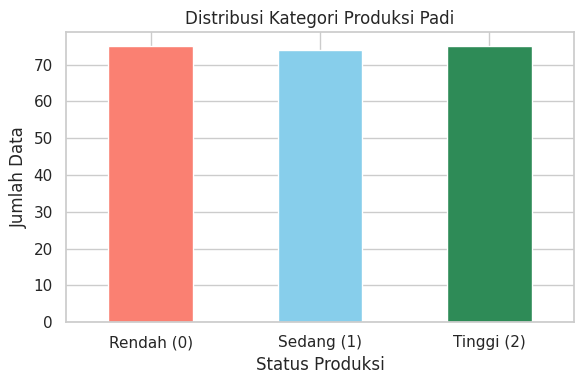


             HASIL EVALUASI 5-FOLD CROSS-VALIDATION        


,Fold,DT Accuracy,NB Accuracy,DT F1-Score,NB F1-Score
0,Fold 1,0.7556,0.8222,0.7570,0.8207
1,Fold 2,0.6667,0.8222,0.6944,0.8243
2,Fold 3,0.8222,0.8444,0.8215,0.8383
3,Fold 4,0.7333,0.7778,0.7300,0.7752
4,Fold 5,0.7727,0.8182,0.7709,0.8155



--- RATA-RATA AKURASI (MEAN ± STD) ---
Decision Tree Mean Accuracy : 75.01% (± 5.10%)
Naive Bayes Mean Accuracy   : 81.70% (± 2.17%)


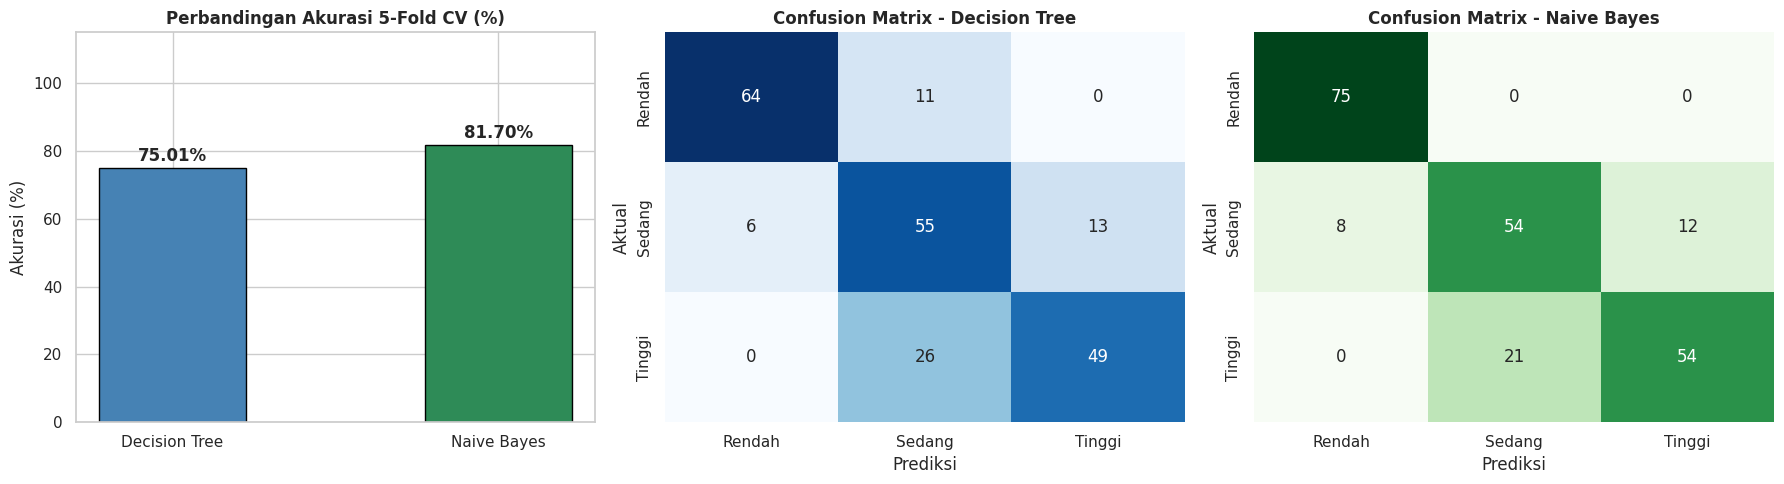

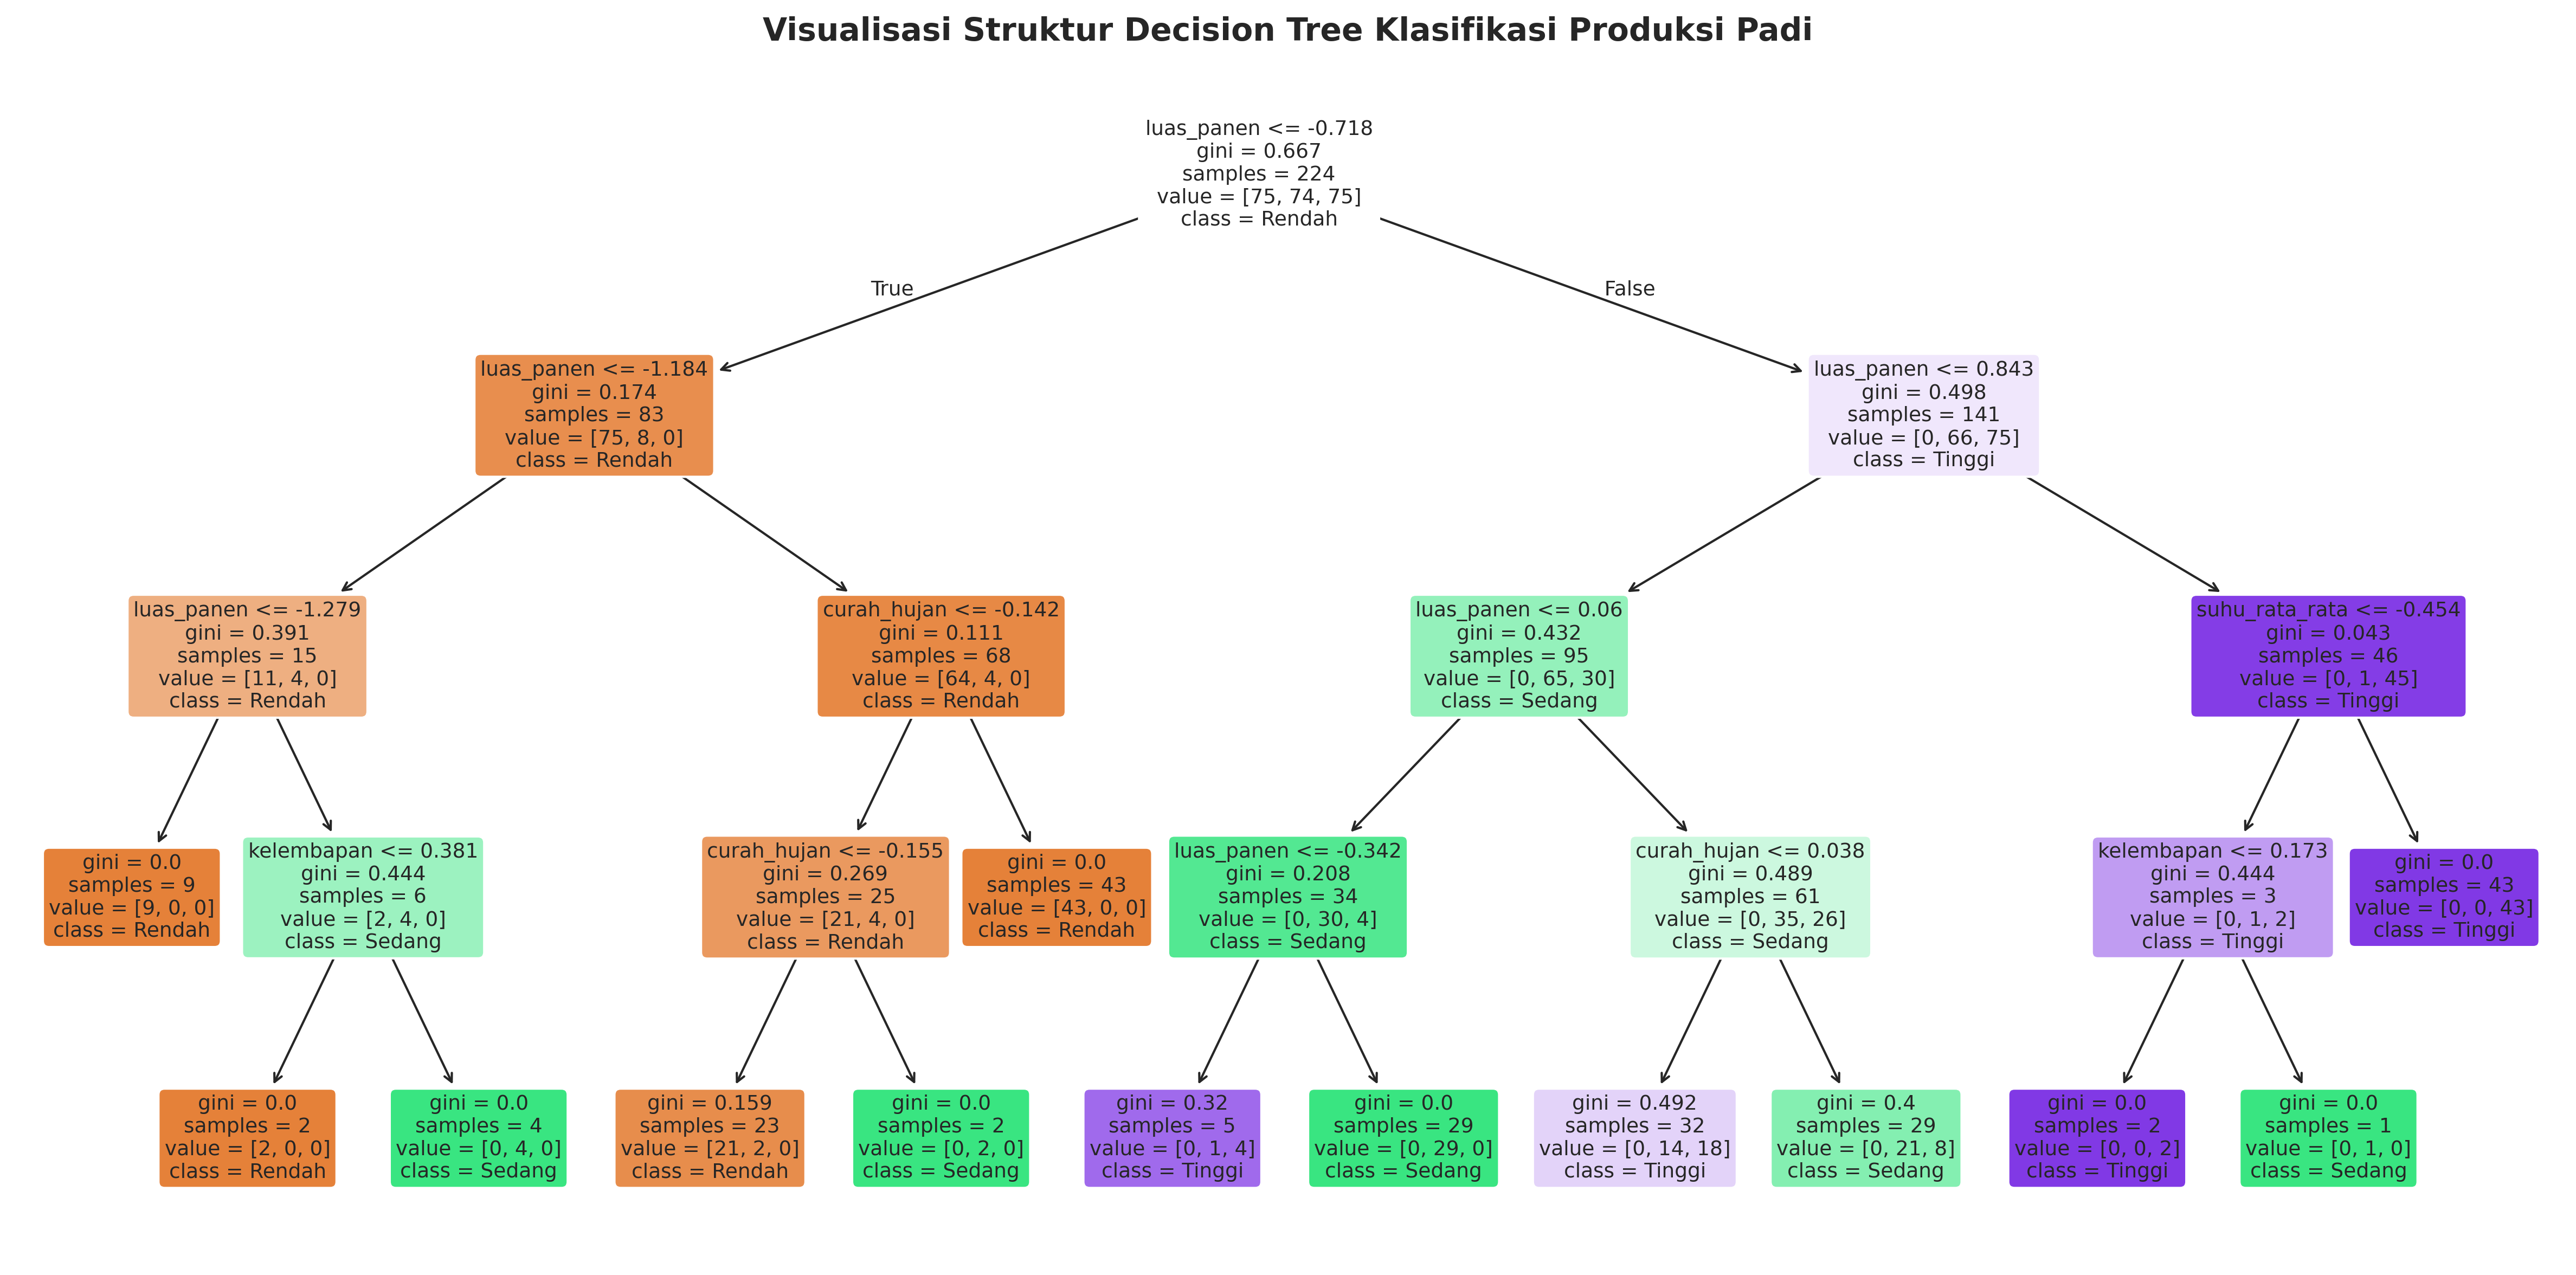

In [2]:
# ==============================================================================
# PROYEK MACHINE LEARNING: KLASIFIKASI PRODUKSI PADI SUMATERA
# ALGORITMA: DECISION TREE VS NAIVE BAYES (5-FOLD CROSS-VALIDATION)
# FOLDER GDRIVE: KCB-1
# ==============================================================================

# ------------------------------------------------------------------------------
# BAGIAN 1: SETUP DEPENDENCIES & CONNECT GOOGLE DRIVE
# ------------------------------------------------------------------------------
import os
import glob
import warnings
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Install kagglehub jika belum terinstall
!pip install kagglehub -q

import kagglehub
from google.colab import drive

from sklearn.model_selection import KFold, cross_validate, cross_val_predict
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import confusion_matrix, classification_report

warnings.filterwarnings('ignore')
sns.set_theme(style="whitegrid")

# 1. Mount Google Drive
drive.mount('/content/drive')

# 2. Buat Folder KCB-1 di Google Drive jika belum ada
drive_folder_path = '/content/drive/MyDrive/KCB-1'
if not os.path.exists(drive_folder_path):
    os.makedirs(drive_folder_path)
    print("✅ Folder 'KCB-1' berhasil dibuat di Google Drive!")
else:
    print("ℹ️ Folder 'KCB-1' sudah siap di Google Drive.")

# ------------------------------------------------------------------------------
# BAGIAN 2: LOAD DATASET OTOMATIS DARI KAGGLEHUB & EKSPLORASI AWAL
# ------------------------------------------------------------------------------
print("\n--- UNDUH DATASET DARI KAGGLEHUB ---")
dataset_dir = kagglehub.dataset_download("ardikasatria/datasettanamanpadisumatera")

# Cari file CSV secara dinamis di dalam folder unduhan
csv_files = glob.glob(os.path.join(dataset_dir, "**", "*.csv"), recursive=True)
if not csv_files:
    raise FileNotFoundError("Tidak ada file CSV yang ditemukan di dalam direktori dataset yang diunduh.")
csv_file_path = csv_files[0]
print(f"Menggunakan dataset dari: {csv_file_path}")

# Memuat dataset
df = pd.read_csv(csv_file_path)

print("Ukuran Dataset Awal:", df.shape)
print("\n1. Informasi Dataset:")
df.info()

print("\n2. Memeriksa Missing Value:")
print(df.isnull().sum())

print("\n3. Memeriksa Duplikasi:")
print(df.duplicated().sum())

print("\n4. 5 Data Pertama:")
display(df.head())

# ------------------------------------------------------------------------------
# BAGIAN 3: PREPROCESSING & DISKRETISASI TARGET
# ------------------------------------------------------------------------------
df_clean = df.copy()

# Penyesuaian nama kolom ke bentuk snake_case
df_clean = df_clean.rename(columns={
    'Provinsi': 'provinsi',
    'Tahun': 'tahun',
    'Luas Panen': 'luas_panen',
    'Curah hujan': 'curah_hujan',
    'Kelembapan': 'kelembapan',
    'Suhu rata-rata': 'suhu_rata_rata',
    'Produksi': 'produksi'
})

# Menangani duplikat (jika ada)
if df_clean.duplicated().sum() > 0:
    df_clean = df_clean.drop_duplicates().reset_index(drop=True)

# Diskretisasi target kontinu 'produksi' menjadi 3 kelas (Rendah, Sedang, Tinggi)
df_clean['kategori_produksi'] = pd.qcut(
    df_clean['produksi'],
    q=3,
    labels=['Rendah', 'Sedang', 'Tinggi']
)

# Menyimpan hasil dataset bersih ke Folder KCB-1 di Drive
output_csv_path = os.path.join(drive_folder_path, 'dataset_padi_bersih.csv')
df_clean.to_csv(output_csv_path, index=False)
print(f"\n✅ Dataset bersih berhasil disimpan ke: {output_csv_path}")

# Visualisasi Distribusi Kategori Produksi Padi
plt.figure(figsize=(6, 4))
df_clean['kategori_produksi'].value_counts().sort_index().plot(
    kind='bar',
    color=['salmon', 'skyblue', 'seagreen']
)
plt.title('Distribusi Kategori Produksi Padi')
plt.xlabel('Status Produksi')
plt.ylabel('Jumlah Data')
plt.xticks([0, 1, 2], ['Rendah (0)', 'Sedang (1)', 'Tinggi (2)'], rotation=0)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------------------------
# BAGIAN 4: PEMODELAN MACHINE LEARNING (5-FOLD CROSS-VALIDATION)
# ------------------------------------------------------------------------------
# Memisahkan Fitur (X) dan Target Label (y)
features_num = ['luas_panen', 'curah_hujan', 'kelembapan', 'suhu_rata_rata']
X = df_clean[features_num]
y = df_clean['kategori_produksi']

# Label Encoding & Feature Scaling
le = LabelEncoder()
y_encoded = le.fit_transform(y)

scaler = StandardScaler()
X_scaled = pd.DataFrame(scaler.fit_transform(X), columns=features_num)

# Inisialisasi Model & 5-Fold Cross-Validation
dt_model = DecisionTreeClassifier(random_state=42, max_depth=4)
nb_model = GaussianNB()
kf = KFold(n_splits=5, shuffle=True, random_state=42)

scoring = {'accuracy': 'accuracy', 'precision': 'precision_weighted', 'recall': 'recall_weighted', 'f1': 'f1_weighted'}

# Evaluasi Model
cv_dt = cross_validate(dt_model, X_scaled, y_encoded, cv=kf, scoring=scoring)
cv_nb = cross_validate(nb_model, X_scaled, y_encoded, cv=kf, scoring=scoring)

# Tampilkan Tabel Hasil
df_cv_results = pd.DataFrame({
    'Fold': [f'Fold {i+1}' for i in range(5)],
    'DT Accuracy': cv_dt['test_accuracy'],
    'NB Accuracy': cv_nb['test_accuracy'],
    'DT F1-Score': cv_dt['test_f1'],
    'NB F1-Score': cv_nb['test_f1']
})

print("\n=========================================================")
print("             HASIL EVALUASI 5-FOLD CROSS-VALIDATION        ")
print("=========================================================")
display(df_cv_results.round(4))

print("\n--- RATA-RATA AKURASI (MEAN ± STD) ---")
print(f"Decision Tree Mean Accuracy : {cv_dt['test_accuracy'].mean()*100:.2f}% (± {cv_dt['test_accuracy'].std()*100:.2f}%)")
print(f"Naive Bayes Mean Accuracy   : {cv_nb['test_accuracy'].mean()*100:.2f}% (± {cv_nb['test_accuracy'].std()*100:.2f}%)")

# ------------------------------------------------------------------------------
# BAGIAN 5: VISUALISASI HASIL & STRUKTUR DECISION TREE
# ------------------------------------------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Grafik Batang Akurasi
models = ['Decision Tree', 'Naive Bayes']
acc_means = [cv_dt['test_accuracy'].mean() * 100, cv_nb['test_accuracy'].mean() * 100]
colors = ['steelblue', 'seagreen']

bars = axes[0].bar(models, acc_means, color=colors, width=0.45, edgecolor='black')
axes[0].set_title('Perbandingan Akurasi 5-Fold CV (%)', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Akurasi (%)')
axes[0].set_ylim(0, 115)

for bar in bars:
    yval = bar.get_height()
    axes[0].text(bar.get_x() + bar.get_width()/2, yval + 2, f"{yval:.2f}%", ha='center', fontweight='bold')

# Confusion Matrix
y_pred_dt = cross_val_predict(dt_model, X_scaled, y_encoded, cv=kf)
y_pred_nb = cross_val_predict(nb_model, X_scaled, y_encoded, cv=kf)

sns.heatmap(confusion_matrix(y_encoded, y_pred_dt), annot=True, fmt='d', cmap='Blues', ax=axes[1],
            xticklabels=le.classes_, yticklabels=le.classes_, cbar=False)
axes[1].set_title('Confusion Matrix - Decision Tree', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Prediksi')
axes[1].set_ylabel('Aktual')

sns.heatmap(confusion_matrix(y_encoded, y_pred_nb), annot=True, fmt='d', cmap='Greens', ax=axes[2],
            xticklabels=le.classes_, yticklabels=le.classes_, cbar=False)
axes[2].set_title('Confusion Matrix - Naive Bayes', fontsize=12, fontweight='bold')
axes[2].set_xlabel('Prediksi')
axes[2].set_ylabel('Aktual')

plt.tight_layout()
plt.show()

# Visualisasi Pohon Keputusan (Decision Tree)
dt_model.fit(X_scaled, y_encoded)
plt.figure(figsize=(16, 8), dpi=300)
plot_tree(
    dt_model,
    feature_names=features_num,
    class_names=le.classes_,
    filled=True,
    rounded=True,
    fontsize=9
)
plt.title('Visualisasi Struktur Decision Tree Klasifikasi Produksi Padi', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()